# ML Lab 7: Naive Bayes, Spam Detection & Sentiment Analysis

**Name:** Muhammad Taraz  
**Student ID:** 023-24-0259  
**Section:** H  
**GitHub Profile:** https://github.com/Muhammad-taraz  
**Kaggle Profile:** https://www.kaggle.com/MuhammadTaraz

**Dataset A:** SMS Spam Collection  
**Dataset B:** Twitter US Airline Sentiment


## 1. Problem Definition & Dataset Exploration

This lab uses two binary text-classification problems. Task A predicts spam or ham SMS messages. Task B predicts positive or negative airline tweets, with neutral tweets removed as required by the manual.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42

spam_raw = pd.read_csv("spam.csv", encoding="latin-1")
tweets_raw = pd.read_csv("Tweets.csv")

print("SMS shape:", spam_raw.shape)
print("Tweets shape:", tweets_raw.shape)
print("SMS columns:", spam_raw.columns.tolist())
print("Tweet columns:", tweets_raw.columns.tolist())


SMS shape: (5572, 5)
Tweets shape: (14640, 15)
SMS columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']
Tweet columns: ['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence', 'negativereason', 'negativereason_confidence', 'airline', 'airline_sentiment_gold', 'name', 'negativereason_gold', 'retweet_count', 'text', 'tweet_coord', 'tweet_created', 'tweet_location', 'user_timezone']


In [4]:
# Prepare SMS data
if "v1" in spam_raw.columns and "v2" in spam_raw.columns:
    spam = spam_raw[["v1", "v2"]].copy()
    spam.columns = ["label", "message"]
else:
    spam = spam_raw.iloc[:, :2].copy()
    spam.columns = ["label", "message"]

spam = spam.dropna()
print("SMS rows:", len(spam))
print("\nSMS counts:")
print(spam["label"].value_counts())
print("\nSMS percentages:")
print((spam["label"].value_counts(normalize=True) * 100).round(2))

# Keep positive and negative tweets only
sentiment = tweets_raw[tweets_raw["airline_sentiment"].isin(["positive","negative"])].copy()
print("\nOriginal tweets:", len(tweets_raw))
print("Positive/negative tweets kept:", len(sentiment))
print(sentiment["airline_sentiment"].value_counts())
print((sentiment["airline_sentiment"].value_counts(normalize=True) * 100).round(2))


SMS rows: 5572

SMS counts:
label
ham     4825
spam     747
Name: count, dtype: int64

SMS percentages:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64

Original tweets: 14640
Positive/negative tweets kept: 11541
airline_sentiment
negative    9178
positive    2363
Name: count, dtype: int64
airline_sentiment
negative    79.53
positive    20.47
Name: proportion, dtype: float64


**Interpretation:** The SMS counts show the balance between ham and spam. Neutral tweets are removed so the sentiment task has only two classes, positive and negative.

### Task 2, Practical problem

**Spam:** The model supports the decision of whether an SMS should be treated as spam or a normal message. It is binary because the labels are spam and ham.

**Sentiment:** The model supports identifying whether an airline tweet is positive or negative. It is binary because neutral tweets are removed.

## 2. Task A: Text Cleaning & Vectorization, Spam

### Task 3
Cleaning is intentionally light. Text is lowercased and punctuation is removed.

In [5]:
def clean_sms(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

spam["clean_message"] = spam["message"].apply(clean_sms)
display(spam[["message","clean_message"]].head())


,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...


**Interpretation:** Lowercasing prevents `Free` and `free` from becoming separate words. Punctuation is removed without doing heavy NLP preprocessing.

### Task 4
The data is split first. The vectorizer is fitted only on training messages and then used on both train and test data. This prevents test-set vocabulary information from leaking into training.

In [6]:
spam["target"] = spam["label"].map({"ham":0, "spam":1})

X_spam = spam["clean_message"]
y_spam = spam["target"]

Xtr_s, Xte_s, ytr_s, yte_s = train_test_split(
    X_spam, y_spam, test_size=0.20, random_state=RANDOM_STATE, stratify=y_spam
)

spam_vec = TfidfVectorizer()
Xtr_sv = spam_vec.fit_transform(Xtr_s)
Xte_sv = spam_vec.transform(Xte_s)

print("Training rows:", len(Xtr_s))
print("Test rows:", len(Xte_s))
print("Vocabulary size:", len(spam_vec.get_feature_names_out()))
print("Train matrix:", Xtr_sv.shape)
print("Test matrix:", Xte_sv.shape)


Training rows: 4457
Test rows: 1115
Vocabulary size: 7658
Train matrix: (4457, 7658)
Test matrix: (1115, 7658)


## 3. Task A: Naive Bayes Model & Evaluation, Spam

### Task 5

,Metric,Score
0,Accuracy,0.960538
1,Precision,1.000000
2,Recall,0.704698
3,F1-score,0.826772


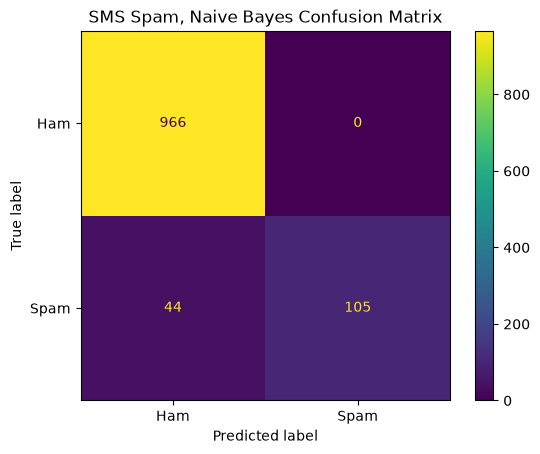

In [7]:
spam_nb = MultinomialNB()
spam_nb.fit(Xtr_sv, ytr_s)
pred_s = spam_nb.predict(Xte_sv)

spam_scores = {
    "Accuracy": accuracy_score(yte_s, pred_s),
    "Precision": precision_score(yte_s, pred_s, zero_division=0),
    "Recall": recall_score(yte_s, pred_s, zero_division=0),
    "F1-score": f1_score(yte_s, pred_s, zero_division=0)
}
spam_metrics = pd.DataFrame({"Metric": spam_scores.keys(), "Score": spam_scores.values()})
display(spam_metrics)

cm = confusion_matrix(yte_s, pred_s)
ConfusionMatrixDisplay(cm, display_labels=["Ham","Spam"]).plot()
plt.title("SMS Spam, Naive Bayes Confusion Matrix")
plt.show()


**Interpretation:** The four metrics show overall correctness and the quality of spam predictions. The confusion matrix shows correct and incorrect ham/spam predictions.

### Task 6, False positive vs false negative

For spam filtering, a false positive can be especially harmful because a real message may be hidden as spam. A false negative lets spam reach the inbox, which is also undesirable. If protecting legitimate messages is the main concern, I would prioritize precision because a higher precision means messages predicted as spam are more likely to actually be spam.

## 4. Task A: Word Interpretation, Spam

### Task 7
`feature_log_prob_` contains the learned log probabilities. The difference between spam and ham log probabilities is used to find the strongest class-associated words.

In [8]:
features = spam_vec.get_feature_names_out()
spam_log = spam_nb.feature_log_prob_[1]
ham_log = spam_nb.feature_log_prob_[0]
diff = spam_log - ham_log

idx_spam = np.argsort(diff)[-15:][::-1]
idx_ham = np.argsort(diff)[:15]

top_spam = pd.DataFrame({
    "Word": features[idx_spam],
    "Spam log P": spam_log[idx_spam],
    "Ham log P": ham_log[idx_spam],
    "Difference": diff[idx_spam]
})
top_ham = pd.DataFrame({
    "Word": features[idx_ham],
    "Spam log P": spam_log[idx_ham],
    "Ham log P": ham_log[idx_ham],
    "Difference": diff[idx_ham]
})

print("15 words most associated with SPAM")
display(top_spam)
print("15 words most associated with HAM")
display(top_ham)


15 words most associated with SPAM


,Word,Spam log P,Ham log P,Difference
0,claim,-6.412797,-9.882671,3.469874
1,prize,-6.616562,-9.882671,3.266109
2,150p,-6.878976,-9.882671,3.003695
3,www,-6.603857,-9.604156,3.000298
4,uk,-6.790462,-9.690050,2.899588
5,tone,-7.018687,-9.882671,2.863985
6,18,-7.074580,-9.882671,2.808092
7,guaranteed,-7.094751,-9.882671,2.787921
8,cs,-7.128845,-9.882671,2.753827
9,1000,-7.152786,-9.882671,2.729885


15 words most associated with HAM


,Word,Spam log P,Ham log P,Difference
0,gt,-9.237325,-6.031440,-3.205885
1,lt,-9.237325,-6.042153,-3.195171
2,my,-8.629041,-5.453243,-3.175798
3,ok,-8.722825,-5.581988,-3.140837
4,ll,-8.952309,-5.853855,-3.098454
5,later,-9.237325,-6.203059,-3.034266
6,lor,-9.237325,-6.260982,-2.976343
7,da,-9.237325,-6.299333,-2.937991
8,but,-8.745856,-5.881513,-2.864343
9,home,-9.102782,-6.238499,-2.864283


**Interpretation:** These tables show the words the fitted model associates most strongly with each class. The exact words come from the actual training data and model probabilities.

### Task 8, Own test messages

In [9]:
messages = [
    "Congratulations you have won a free cash prize claim your reward now",
    "Hey are we still meeting at 5 pm today",
    "Please bring the notes to class tomorrow"
]

clean_messages = [clean_sms(x) for x in messages]
vec_messages = spam_vec.transform(clean_messages)
pred_messages = spam_nb.predict(vec_messages)

display(pd.DataFrame({
    "Message": messages,
    "Prediction": ["spam" if x == 1 else "ham" for x in pred_messages]
}))


,Message,Prediction
0,Congratulations you have won a free cash prize...,spam
1,Hey are we still meeting at 5 pm today,ham
2,Please bring the notes to class tomorrow,ham


**Interpretation:** The first message is intentionally spam-like, while the other two are normal messages. If the model makes an unexpected prediction, it is using learned word patterns rather than human-level understanding.

## 5. Task A: Kaggle Notebook Submission

### Tasks 9 and 10

On the SMS Spam Collection Kaggle dataset page, create **New Notebook**, recreate these Task A cells, run everything top to bottom, add a 2–3 sentence summary, then use **Save Version → Save & Run All (Public)**.

**Task A public Kaggle Notebook URL:**  
`https://www.kaggle.com/code/muhammadtaraz/muhammadtaraz-sms-spam`

Do not invent the URL. Paste the real public URL after publishing.

## 6. Task B: Text Cleaning & Vectorization, Sentiment

### Task 11
Tweets can contain @mentions, links and hashtags. Here @mentions and URLs are removed, while hashtag words are kept.

In [10]:
def clean_tweet(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"#", "", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

sentiment["clean_text"] = sentiment["text"].apply(clean_tweet)
display(sentiment[["text","clean_text"]].head())


,text,clean_text
1,@VirginAmerica plus you've added commercials t...,plus you ve added commercials to the experienc...
3,@VirginAmerica it's really aggressive to blast...,it s really aggressive to blast obnoxious ente...
4,@VirginAmerica and it's a really big bad thing...,and it s a really big bad thing about it
5,@VirginAmerica seriously would pay $30 a fligh...,seriously would pay 30 a flight for seats that...
6,"@VirginAmerica yes, nearly every time I fly VX...",yes nearly every time i fly vx this ear worm w...


**Interpretation:** Tweet cleaning goes slightly further than SMS cleaning because tweets commonly contain links and @mentions. These can add noisy vocabulary features.

### Task 12

The extra cleaning removes URLs and @mentions because they are common in tweets and can create many features that are less useful for the basic positive/negative sentiment decision.

In [11]:
sentiment["target"] = sentiment["airline_sentiment"].map({"negative":0, "positive":1})

X_sent = sentiment["clean_text"]
y_sent = sentiment["target"]

Xtr_t, Xte_t, ytr_t, yte_t = train_test_split(
    X_sent, y_sent, test_size=0.20, random_state=RANDOM_STATE, stratify=y_sent
)

sent_vec = TfidfVectorizer()
Xtr_tv = sent_vec.fit_transform(Xtr_t)
Xte_tv = sent_vec.transform(Xte_t)

print("Training tweets:", len(Xtr_t))
print("Test tweets:", len(Xte_t))
print("Vocabulary size:", len(sent_vec.get_feature_names_out()))
print("Train matrix:", Xtr_tv.shape)
print("Test matrix:", Xte_tv.shape)


Training tweets: 9232
Test tweets: 2309
Vocabulary size: 10079
Train matrix: (9232, 10079)
Test matrix: (2309, 10079)


**Interpretation:** The sentiment vectorizer is fitted only on training tweets. This follows the same no-leakage rule used in Task A.

## 7. Task B: Naive Bayes Model & Evaluation

### Task 13

,Metric,Score
0,Accuracy,0.831096
1,Precision,1.000000
2,Recall,0.175476
3,F1-score,0.298561


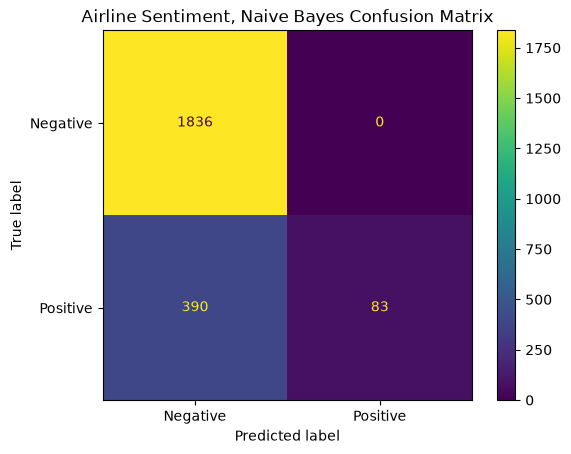

In [12]:
sent_nb = MultinomialNB()
sent_nb.fit(Xtr_tv, ytr_t)
pred_t = sent_nb.predict(Xte_tv)

sent_scores = {
    "Accuracy": accuracy_score(yte_t, pred_t),
    "Precision": precision_score(yte_t, pred_t, zero_division=0),
    "Recall": recall_score(yte_t, pred_t, zero_division=0),
    "F1-score": f1_score(yte_t, pred_t, zero_division=0)
}
sent_metrics = pd.DataFrame({"Metric": sent_scores.keys(), "Score": sent_scores.values()})
display(sent_metrics)

cm_t = confusion_matrix(yte_t, pred_t)
ConfusionMatrixDisplay(cm_t, display_labels=["Negative","Positive"]).plot()
plt.title("Airline Sentiment, Naive Bayes Confusion Matrix")
plt.show()


**Interpretation:** The sentiment model is evaluated using all four required metrics and a confusion matrix. This makes the result comparable with the spam task and the earlier ML labs.

### Task 14

Spam text is often short and formulaic, so treating words as conditionally independent can work reasonably well. Tweets contain more context, negation such as “not good”, sarcasm and informal wording, so the independence assumption can be less realistic. The actual metric comparison below shows how this affected the two tasks in this experiment.

In [13]:
task_compare = pd.DataFrame({
    "Task": ["SMS Spam", "Airline Sentiment"],
    "Accuracy": [spam_scores["Accuracy"], sent_scores["Accuracy"]],
    "Precision": [spam_scores["Precision"], sent_scores["Precision"]],
    "Recall": [spam_scores["Recall"], sent_scores["Recall"]],
    "F1-score": [spam_scores["F1-score"], sent_scores["F1-score"]]
})
display(task_compare)


,Task,Accuracy,Precision,Recall,F1-score
0,SMS Spam,0.960538,1.0,0.704698,0.826772
1,Airline Sentiment,0.831096,1.0,0.175476,0.298561


**Interpretation:** The higher scores indicate which task was easier for this Naive Bayes setup. The difference is discussed using the nature of the text and the conditional-independence assumption.

## 8. Task B: Kaggle Notebook Submission

### Tasks 15 and 16

On the Twitter US Airline Sentiment Kaggle dataset page, create a new Kaggle Notebook, recreate Task B, run all cells, add a short summary, and publish using **Save Version → Save & Run All (Public)**.

**Task B public Kaggle Notebook URL:**  
`https://www.kaggle.com/code/muhammadtaraz/muhammadtaraz-airline-sentiment`

Paste the actual public URL after publishing.

## 9. Cross-Task Comparison & vs. Logistic Regression

### Task 17

In [ ]:
nb_task_compare = pd.DataFrame({
    "Metric": ["Accuracy","Precision","Recall","F1-score"],
    "SMS Spam": [spam_scores["Accuracy"],spam_scores["Precision"],spam_scores["Recall"],spam_scores["F1-score"]],
    "Airline Sentiment": [sent_scores["Accuracy"],sent_scores["Precision"],sent_scores["Recall"],sent_scores["F1-score"]]
})
display(nb_task_compare)


,Metric,SMS Spam,Airline Sentiment
0,Accuracy,0.960538,0.831096
1,Precision,1.000000,1.000000
2,Recall,0.704698,0.175476
3,F1-score,0.826772,0.298561


**Interpretation:** This table compares Naive Bayes directly across both text problems using the same four metrics.

### Task 18

Logistic Regression is trained on the exact same Task A TF-IDF training and test features. This makes the comparison fair because both models receive the same feature representation and split.

In [15]:
spam_lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
spam_lr.fit(Xtr_sv, ytr_s)
pred_lr = spam_lr.predict(Xte_sv)

lr_scores = {
    "Accuracy": accuracy_score(yte_s, pred_lr),
    "Precision": precision_score(yte_s, pred_lr, zero_division=0),
    "Recall": recall_score(yte_s, pred_lr, zero_division=0),
    "F1-score": f1_score(yte_s, pred_lr, zero_division=0)
}

spam_model_compare = pd.DataFrame({
    "Metric": ["Accuracy","Precision","Recall","F1-score"],
    "Naive Bayes": [spam_scores["Accuracy"],spam_scores["Precision"],spam_scores["Recall"],spam_scores["F1-score"]],
    "Logistic Regression": [lr_scores["Accuracy"],lr_scores["Precision"],lr_scores["Recall"],lr_scores["F1-score"]]
})
display(spam_model_compare)

if lr_scores["F1-score"] > spam_scores["F1-score"]:
    print("Based on F1-score, Logistic Regression is higher on Task A.")
elif lr_scores["F1-score"] < spam_scores["F1-score"]:
    print("Based on F1-score, Naive Bayes is higher on Task A.")
else:
    print("Both models have the same F1-score on Task A.")


,Metric,Naive Bayes,Logistic Regression
0,Accuracy,0.960538,0.972197
1,Precision,1.000000,0.991667
2,Recall,0.704698,0.798658
3,F1-score,0.826772,0.884758


Based on F1-score, Logistic Regression is higher on Task A.


**Interpretation:** Both models use the same Task A TF-IDF features, so their difference comes from the modelling approach. Naive Bayes assumes conditional independence between features, while Logistic Regression does not use that same assumption.

## 10. Final Reflection & Conclusion

### Task 19

Naive Bayes was applied to both spam detection and airline sentiment using the same basic text-classification workflow. The actual results show which task suited Naive Bayes better in this experiment. Spam messages are usually more formulaic, while tweets contain context, negation and informal language that can be harder for the independence assumption. The most predictive words also showed which vocabulary patterns the model learned for spam and ham. Logistic Regression was compared with Naive Bayes on the same SMS features, so the comparison was based on the same data representation. One limitation of Naive Bayes is that it treats word features as conditionally independent and therefore does not fully understand word order or phrases such as “not good”. This lab showed how text needs to be converted into numeric features before classification and how the same model can behave differently on different text problems.

### Task 20, Published Kaggle Notebook URLs

**Task A, SMS Spam Collection:**  
`https://www.kaggle.com/code/muhammadtaraz/muhammadtaraz-sms-spam`

**Task B, Twitter US Airline Sentiment:**  
`https://www.kaggle.com/code/muhammadtaraz/muhammadtaraz-airline-sentiment`


# Final Checklist

- Student info block completed
- Both datasets loaded and explored
- Exact class counts and percentages generated
- Neutral tweets removed
- Practical problem explained for both tasks
- SMS cleaning and train-only vectorization
- Spam Naive Bayes with all four metrics and confusion matrix
- Spam precision vs recall reasoning
- 15 spam-associated and 15 ham-associated words
- Three custom SMS messages tested
- Task A Kaggle notebook publication
- Tweet-specific cleaning and train-only vectorization
- Sentiment Naive Bayes with all four metrics and confusion matrix
- Spam vs sentiment comparison
- Task B Kaggle notebook publication
- Naive Bayes cross-task comparison
- Logistic Regression on the same Task A features
- Final conclusion
- Both public Kaggle URLs recorded
- Written interpretations included after outputs